# Brain metastases: stage 1 (3D U-Net) + stage 2 (false-positive classifier), multi-sequence and resumable

**Inputs:** [T1ce, T1, Sub] + the sequences listed in `EXTRA_SEQ` (Cell 2): `bravo`, `flair`. Each run keeps its cache and all checkpoints in its own folder `OUT_ROOT / RUN_NAME`.

**Ablation (change only `RUN_NAME` and `EXTRA_SEQ` in Cell 2, restart the kernel between runs):**
| run | RUN_NAME | EXTRA_SEQ |
|---|---|---|
| 3-channel baseline | `""` | `[]` |
| + BRAVO | `"bravo"` | `["bravo"]` |
| + BRAVO + FLAIR | `"bravo_flair"` | `["bravo", "flair"]` |

**Fresh start:** run the cells top to bottom (run Cell 4-pre first to check disk space; the 5-channel cache is large).
**After a restart / closed VS Code:** run Cells 1 to 10b (they only define things; Cell 4 reuses complete cached files), then **Cell 11** (continues stage 1 from the last epoch). For stage 2 run Cells 13b, 14, 15 (loads cached proposals), 16, 17 (continues stage 2), 18 onwards.
**Check progress anytime:** Cell 11s.
Do not change `EPOCHS`, `LR`, `PATCH` or the channels between a stop and a resume. To restart from scratch set `FORCE_RETRAIN = True` (Cell 11) once and set it back to `False` afterwards.

## Setup, data and preprocessing

In [9]:
# CELL 1 - Imports, seed, device
import re, glob, random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from scipy import ndimage
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")

Device: cuda - NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [10]:
# CELL 2 - Config
RUN_NAME  = "bravo_flair"          # output folder for this run: its cache + ALL checkpoints go here (use "" for the original 3-channel locations)
EXTRA_SEQ = ["bravo", "flair"]     # sequences appended after [T1ce, T1, Sub]; ["bravo"] or [] for the ablation runs
BASE  = Path(r"D:\Brain Metastases\Notebook\Dataset\BrainMetShare")
OUT_ROOT = BASE.parent             # where runs are stored; point this at a drive with free space, e.g. Path(r"D:\brainmets_runs")
CACHE = OUT_ROOT / RUN_NAME / "cache_npy"           # CACHE.parent holds stage1_best.pt, stage2_cache, ... of this run
CACHE.mkdir(parents=True, exist_ok=True)

IN_CH = 3 + len(EXTRA_SEQ)                           # number of input channels
CHANNEL_NAMES = ["T1ce", "T1", "Sub"] + [s.upper() for s in EXTRA_SEQ]
print("run folder:", CACHE.parent, "| channels:", CHANNEL_NAMES)

PATCH   = (64, 128, 128)    # deeper z context (each dim divisible by 8)
SPACING = (1.0, 1.0, 1.0)
BATCH_SIZE = 1
EPOCHS     = 300
SAMPLES_PER_EPOCH = 300     # 300 x 300 = 90k iterations
LR         = 1e-3
EVAL_EVERY = 10             # full-volume validation every N epochs
EVAL_THR   = 0.2            # low threshold used for checkpoint selection
FP_BUDGET  = 30             # FP/patient above this is penalised in checkpoint score

run folder: D:\Brain Metastases\Notebook\Dataset\bravo_flair | channels: ['T1ce', 'T1', 'Sub', 'BRAVO', 'FLAIR']


In [11]:
# CELL 3 - Find subjects + patient-wise train / val / test split
assert BASE.exists(), f"Path not found: {BASE}"

def find_nii(sdir, name):
    for ext in (".nii", ".nii.gz"):
        f = sdir / f"{name}{ext}"
        if f.exists():
            return f
    return None

def list_subjects(split):
    d = BASE / split
    return sorted(p for p in d.iterdir() if p.is_dir()) if d.exists() else []

train_folder = list_subjects("train")
test_folder  = list_subjects("test")
print(f"'train' folder: {len(train_folder)} subjects | 'test' folder: {len(test_folder)} subjects")

# The official 'test' folder has no seg.nii, so it cannot be scored.
# Split the labelled 'train' subjects by patient instead.
labelled = [p for p in train_folder
            if all(find_nii(p, n) for n in ("t1_pre", "t1_gd", "seg"))]
rng = random.Random(SEED)
rng.shuffle(labelled)
n = len(labelled)
n_test, n_val = max(1, int(0.15 * n)), max(1, int(0.15 * n))
test_subj  = labelled[:n_test]
val_subj   = labelled[n_test:n_test + n_val]
train_subj = labelled[n_test + n_val:]
print(f"labelled={n} -> train={len(train_subj)}, val={len(val_subj)}, test={len(test_subj)}")
print("BASE exists:", BASE.exists())
print("top level  :", [p.name for p in BASE.iterdir()][:10])

for split in ("train", "test"):
    d = BASE / split
    print(f"\n{split}: exists={d.exists()}")
    if d.exists():
        subs = [p for p in d.iterdir() if p.is_dir()]
        print("  subjects:", len(subs), [p.name for p in subs[:3]])
        if subs:
            print("  inside first subject:", [p.name for p in subs[0].iterdir()])
            for sub in subs[0].iterdir():
                if sub.is_dir():
                    print("   ", sub.name, "->", [f.name for f in list(sub.iterdir())[:3]])

'train' folder: 105 subjects | 'test' folder: 51 subjects
labelled=105 -> train=75, val=15, test=15
BASE exists: True
top level  : ['test', 'train']

train: exists=True
  subjects: 105 ['Mets_001', 'Mets_002', 'Mets_003']
  inside first subject: ['bravo.nii', 'flair.nii', 'seg.nii', 't1_gd.nii', 't1_pre.nii']

test: exists=True
  subjects: 51 ['Mets_001', 'Mets_002', 'Mets_003']
  inside first subject: ['bravo.nii', 'flair.nii', 't1_gd.nii', 't1_pre.nii']


In [12]:
# CELL 4-pre - Disk space check (run before Cell 4)
import shutil, nibabel as nib
def folder_gb(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1e9

tot, used, free = shutil.disk_usage(CACHE.parent)
print(f"drive {CACHE.parent.anchor}  free {free/1e9:.1f} GB of {tot/1e9:.0f} GB")

shape = nib.load(str(find_nii(train_subj[0], "t1_gd"))).shape
vox = int(np.prod(shape)); n_sub = len(train_subj) + len(val_subj) + len(test_subj)
need_gb = (IN_CH * vox * 2 + vox) * n_sub / 1e9                  # float16 image channels + uint8 mask, all subjects
print(f"volume shape {shape} -> this cache needs about {need_gb:.1f} GB ({IN_CH} channels, {n_sub} subjects)")

print("\nwhat is using space next to your dataset:")
for p in sorted(BASE.parent.iterdir()):
    if p.is_dir():
        print(f"  {p.name:<28} {folder_gb(p):7.1f} GB")
    elif p.is_file() and p.stat().st_size > 5e7:
        print(f"  {p.name:<28} {p.stat().st_size/1e9:7.1f} GB")
if free / 1e9 < need_gb * 1.1:
    print("\nNOT ENOUGH FREE SPACE: free some space or point OUT_ROOT (Cell 2) at a drive with room.")

drive D:\  free 218.3 GB of 268 GB
volume shape (256, 256, 150) -> this cache needs about 11.4 GB (5 channels, 105 subjects)

what is using space next to your dataset:


  BrainMetShare                   28.7 GB
  bravo_flair                     11.4 GB
  cache_npy                        7.2 GB
  stage2_cache                     0.6 GB
  stage3_cache                     1.5 GB


In [13]:
# CELL 4 - Preprocessing (NIfTI, native resolution, no resizing); channels = [T1ce, T1, Sub] + EXTRA_SEQ
import os, nibabel as nib

def load_nii(path):
    """Returns (volume as (D,H,W) float32, voxel spacing (z,y,x) in mm)."""
    img = nib.load(str(path))
    vol = np.asanyarray(img.dataobj).astype(np.float32)
    vol = np.transpose(vol, (2, 1, 0))                    # (X,Y,Z) -> (Z,Y,X)
    spacing = tuple(float(z) for z in img.header.get_zooms()[:3][::-1])
    return vol, spacing

def zscore(vol, mask, eps=1e-8):
    """Z-score using brain voxels only, background set to 0."""
    if mask.sum() < 100:
        mask = np.ones_like(mask, dtype=bool)
    out = (vol - vol[mask].mean()) / (vol[mask].std() + eps)
    out[~mask] = 0.0
    return out

def save_npy_atomic(path, arr):
    """Write to a temp file, then rename: a full disk or an interrupted run never leaves a half-written .npy behind."""
    tmp = Path(str(path) + ".tmp")
    try:
        with open(tmp, "wb") as fh:
            np.save(fh, arr)
        os.replace(tmp, path)
    except Exception:
        if tmp.exists():
            tmp.unlink()
        raise

def cache_ok(f_img, f_seg):
    """True only if both cached files exist, are complete (mmap succeeds) and have the expected number of channels."""
    try:
        a = np.load(f_img, mmap_mode="r"); b = np.load(f_seg, mmap_mode="r")
        return a.shape[0] == IN_CH and a.shape[1:] == b.shape
    except Exception:
        return False

def preprocess_subject(sdir, overwrite=False):
    """Saves <name>_img.npy (IN_CH,D,H,W float16: [T1ce, T1, Sub] + EXTRA_SEQ) and <name>_seg.npy (D,H,W uint8)."""
    name = sdir.name
    f_img, f_seg = CACHE / f"{name}_img.npy", CACHE / f"{name}_seg.npy"
    if not overwrite and cache_ok(f_img, f_seg):
        return name
    paths = [find_nii(sdir, n) for n in ("t1_pre", "t1_gd", "seg")]
    if any(p is None for p in paths):
        print(f"[skip] {name}: missing t1_pre / t1_gd / seg"); return None
    (pre, _), (gd, _), (seg, _) = [load_nii(p) for p in paths]
    if not (pre.shape == gd.shape == seg.shape):
        print(f"[skip] {name}: shape mismatch {pre.shape} {gd.shape} {seg.shape}"); return None

    brain = gd > 0
    extras = []
    for q in EXTRA_SEQ:
        f = find_nii(sdir, q)
        if f is None:
            print(f"[skip] {name}: missing {q}"); return None
        v, _ = load_nii(f)
        if v.shape != gd.shape:
            print(f"[skip] {name}: {q} shape {v.shape} != {gd.shape}"); return None
        extras.append(zscore(v, brain))                          # same brain mask (T1ce > 0) for every sequence

    sub = gd - pre                       # subtract the RAW images first (as in the paper) ...
    img = np.stack([zscore(gd, brain),   # ... then Z-score every channel separately
                    zscore(pre, brain),
                    zscore(sub, brain)] + extras).astype(np.float16)
    save_npy_atomic(f_img, img)
    save_npy_atomic(f_seg, (seg > 0).astype(np.uint8))
    return name

# Show the real voxel spacing so you can set SPACING in Cell 2
if train_subj:
    v, sp = load_nii(find_nii(train_subj[0], "t1_gd"))
    print("first volume (D,H,W):", v.shape, "| spacing (z,y,x) mm:", tuple(round(s, 3) for s in sp))

for group in (train_subj, val_subj, test_subj):
    group[:] = [s for s in tqdm(group, desc="preprocessing") if preprocess_subject(s)]
print(f"ready: train={len(train_subj)}, val={len(val_subj)}, test={len(test_subj)} | channels={IN_CH}")

first volume (D,H,W): (150, 256, 256) | spacing (z,y,x) mm: (1.0, 0.938, 0.938)


preprocessing: 100%|██████████| 15/15 [00:00<00:00, 238.23it/s]

ready: train=75, val=15, test=15 | channels=5


In [14]:
# CELL 4b - Class-imbalance check (lesion voxels vs brain voxels, lesion sizes)
fg, tot, sizes = 0, 0, []
for s in train_subj:
    seg = np.load(CACHE / f"{s.name}_seg.npy"); img = np.load(CACHE / f"{s.name}_img.npy", mmap_mode="r")
    fg += int(seg.sum()); tot += int((np.asarray(img[0]) != 0).sum())
    lab, n = ndimage.label(seg, structure=np.ones((3, 3, 3)))
    sizes += list(ndimage.sum(seg, lab, range(1, n + 1)))
sizes = np.array(sizes)
print(f"lesion voxels / brain voxels = {fg/tot:.4%}")
print(f"lesions={len(sizes)} | <30 vox: {(sizes<30).mean():.0%} | 30-100: {((sizes>=30)&(sizes<100)).mean():.0%} | >=100: {(sizes>=100).mean():.0%}")

lesion voxels / brain voxels = 0.2594%
lesions=1093 | <30 vox: 50% | 30-100: 28% | >=100: 22%


## Stage 1: dataset, model, loss, metrics, inference

In [15]:
# CELL 5 - Imbalance-aware patch dataset
class PatchDataset(Dataset):
    def __init__(self, subjects, patch=PATCH, n_samples=None, p_lesion=0.6, p_hard=0.15,
                 small_vox=100, small_boost=2.0, augment=True, seed=None):
        self.names = [s.name for s in subjects]
        self.imgs = [np.load(CACHE / f"{n}_img.npy", mmap_mode="r") for n in self.names]
        self.segs = [np.load(CACHE / f"{n}_seg.npy", mmap_mode="r") for n in self.names]
        self.lesions, self.brain = [], []
        crng = np.random.default_rng(0)
        for img, seg in zip(self.imgs, self.segs):
            seg = np.asarray(seg)
            lab, n = ndimage.label(seg, structure=np.ones((3, 3, 3)))
            if n:
                idx = list(range(1, n + 1))
                cents = np.round(np.array(ndimage.center_of_mass(seg > 0, lab, idx))).astype(int)
                sz = np.array(ndimage.sum(seg > 0, lab, idx))
                w = np.where(sz < small_vox, small_boost, 1.0); w = w / w.sum()   # one draw = one LESION
            else:
                cents, w = np.zeros((0, 3), int), np.zeros(0)
            self.lesions.append((cents, w))
            b = np.argwhere(np.asarray(img[0]) != 0)                              # brain voxels only
            if len(b) > 50000:
                b = b[crng.choice(len(b), 50000, replace=False)]
            self.brain.append(b)
        self.hard = [np.zeros((0, 3), int) for _ in self.names]                   # filled by hard-negative mining
        self.patch, self.p_lesion, self.p_hard, self.augment, self.seed = patch, p_lesion, p_hard, augment, seed
        self.n_samples = n_samples or len(self.names)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, i):
        rng = np.random.default_rng(None if self.seed is None else self.seed + i)
        k = i % len(self.names) if self.seed is not None else int(rng.integers(len(self.names)))
        img, seg, shape = self.imgs[k], self.segs[k], self.segs[k].shape
        cents, w = self.lesions[k]; hard = self.hard[k]; brain = self.brain[k]
        jit = [p // 4 for p in self.patch]
        r = rng.random()
        if len(cents) and r < self.p_lesion:                                      # centre on a random lesion
            c = cents[rng.choice(len(cents), p=w)]
            centre = [int(a + rng.integers(-j, j + 1)) for a, j in zip(c, jit)]
        elif len(hard) and r < self.p_lesion + self.p_hard:                       # centre on a past false positive
            c = hard[rng.integers(len(hard))]
            centre = [int(a + rng.integers(-j, j + 1)) for a, j in zip(c, jit)]
        elif len(brain):                                                          # background, inside brain
            centre = brain[rng.integers(len(brain))]
        else:
            centre = [int(rng.integers(s)) for s in shape]
        start = [int(np.clip(c - p // 2, 0, max(s - p, 0))) for c, p, s in zip(centre, self.patch, shape)]
        sl = tuple(slice(st, st + p) for st, p in zip(start, self.patch))

        x = np.array(img[(slice(None),) + sl], dtype=np.float32)
        y = np.array(seg[sl], dtype=np.float32)
        pad = [(0, p - s) for p, s in zip(self.patch, y.shape)]
        if any(b for _, b in pad):
            x, y = np.pad(x, [(0, 0)] + pad), np.pad(y, pad)

        if self.augment:
            if rng.random() < 0.5:                                                # left-right flip only
                x, y = np.flip(x, 3), np.flip(y, 2)
            m = (x != 0)
            c_ = x.shape[0]
            x = x * rng.uniform(0.9, 1.1, (c_, 1, 1, 1)).astype(np.float32) \
                + rng.normal(0, 0.1, (c_, 1, 1, 1)).astype(np.float32) * m
            x = x + rng.normal(0, 0.03, x.shape).astype(np.float32) * m
        return torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)), torch.from_numpy(np.ascontiguousarray(y))[None]

train_ds = PatchDataset(train_subj, n_samples=SAMPLES_PER_EPOCH)
val_ds   = PatchDataset(val_subj, n_samples=len(val_subj) * 4, p_lesion=0.5, p_hard=0.0, augment=False, seed=123)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("patch:", tuple(xb.shape), tuple(yb.shape), "| lesion voxels in patch:", int(yb.sum()))

patch: (1, 5, 64, 128, 128) (1, 1, 64, 128, 128) | lesion voxels in patch: 107


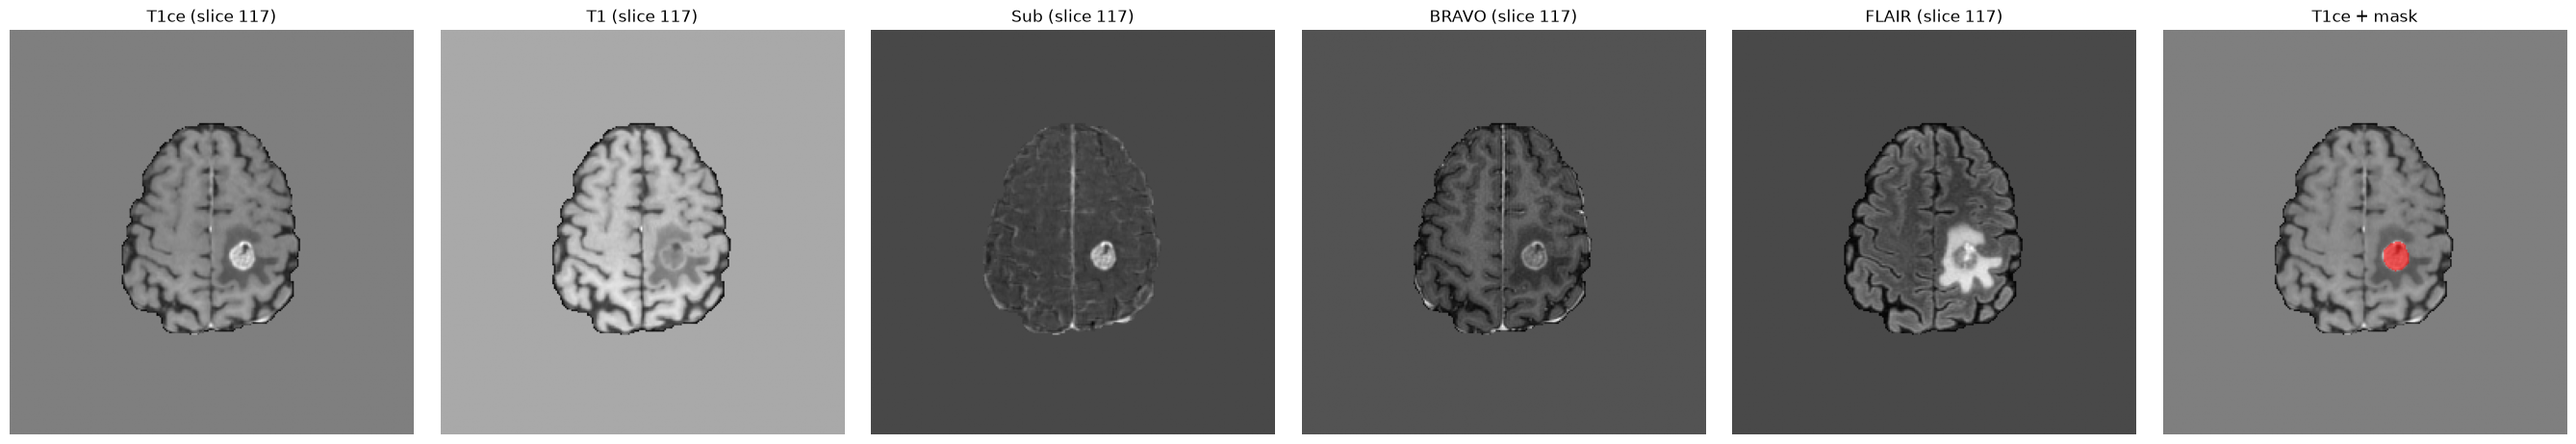

Mets_038 volume: (150, 256, 256) | channels: 5 | lesion voxels: 2873


In [16]:
# CELL 6 - Sanity check: every input channel + mask overlay on the slice with most lesion
name = train_subj[0].name
img = np.load(CACHE / f"{name}_img.npy").astype(np.float32)
seg = np.load(CACHE / f"{name}_seg.npy")
z = int(seg.sum(axis=(1, 2)).argmax())
fig, ax = plt.subplots(1, IN_CH + 1, figsize=(4.5 * (IN_CH + 1), 4.5))
for i, t in enumerate(CHANNEL_NAMES):
    ax[i].imshow(img[i, z], cmap="gray"); ax[i].set_title(f"{t} (slice {z})"); ax[i].axis("off")
ax[IN_CH].imshow(img[0, z], cmap="gray"); ax[IN_CH].imshow(np.ma.masked_equal(seg[z], 0), cmap="autumn", alpha=0.6)
ax[IN_CH].set_title("T1ce + mask"); ax[IN_CH].axis("off")
plt.tight_layout(); plt.show()
print(name, "volume:", seg.shape, "| channels:", img.shape[0], "| lesion voxels:", int(seg.sum()))

In [17]:
# CELL 7 - Stage 1 model (residual 3D U-Net, InstanceNorm, returns LOGITS)
class ResBlock3D(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Conv3d(cin, cout, 3, padding=1, bias=False); self.n1 = nn.InstanceNorm3d(cout, affine=True)
        self.c2 = nn.Conv3d(cout, cout, 3, padding=1, bias=False); self.n2 = nn.InstanceNorm3d(cout, affine=True)
        self.skip = nn.Identity() if cin == cout else nn.Conv3d(cin, cout, 1, bias=False)
    def forward(self, x):
        o = F.relu(self.n1(self.c1(x)), inplace=True)
        return F.relu(self.n2(self.c2(o)) + self.skip(x), inplace=True)

class Stage1UNet(nn.Module):
    def __init__(self, in_ch=IN_CH, base=8, out_ch=1):                 # IN_CH from Cell 2
        super().__init__()
        c = [base, base * 2, base * 4, base * 8]                       # 8-16-32-64
        self.e1, self.e2, self.e3, self.e4 = (ResBlock3D(in_ch, c[0]), ResBlock3D(c[0], c[1]),
                                              ResBlock3D(c[1], c[2]), ResBlock3D(c[2], c[3]))
        self.pool = nn.MaxPool3d(2)
        self.u3, self.d3 = nn.ConvTranspose3d(c[3], c[2], 2, stride=2), ResBlock3D(c[2] * 2, c[2])
        self.u2, self.d2 = nn.ConvTranspose3d(c[2], c[1], 2, stride=2), ResBlock3D(c[1] * 2, c[1])
        self.u1, self.d1 = nn.ConvTranspose3d(c[1], c[0], 2, stride=2), ResBlock3D(c[0] * 2, c[0])
        self.head = nn.Conv3d(c[0], out_ch, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)                                           # sigmoid is applied in loss / inference

with torch.no_grad():
    print("output:", tuple(Stage1UNet()(torch.randn(1, IN_CH, *PATCH)).shape))

output: (1, 1, 64, 128, 128)


In [18]:
# CELL 8 - Bias-dice + BCE (pos_weight) loss
class BiasDiceBCELoss(nn.Module):
    def __init__(self, bias=5.0, pos_weight=10.0, smooth=1.0, w_bce=1.0):
        super().__init__()
        self.bias, self.pw, self.smooth, self.w_bce = bias, pos_weight, smooth, w_bce   # lower pos_weight to 3-5 if FPs explode
    def forward(self, logits, target):
        g = target.float(); p = torch.sigmoid(logits)
        tp = (p * g).sum(); fp = (p * (1 - g)).sum(); fn = ((1 - p) * g).sum()          # batch-level, not per sample
        dice = 1 - (2 * tp + self.smooth) / (2 * tp + fp + self.bias * fn + self.smooth)
        bce = F.binary_cross_entropy_with_logits(logits, g, pos_weight=torch.tensor(self.pw, device=logits.device))
        return dice + self.w_bce * bce

g = torch.zeros(1, 1, 8, 8, 8); g[..., 2:5, 2:5, 2:5] = 1
L = BiasDiceBCELoss()
print("perfect:", L(g * 20 - 10, g).item(), "| all-zero pred:", L(torch.full_like(g, -10), g).item(),
      "| empty target, zero pred:", L(torch.full_like(g, -10), torch.zeros_like(g)).item())

perfect: 0.0005788302514702082 | all-zero pred: 6.26613712310791 | empty target, zero pred: 0.02276146411895752


In [19]:
# CELL 9 - Metrics (one copy, vectorised: no per-lesion loop over the full volume)
S26 = np.ones((3, 3, 3))

def dice_rvd(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter, ps, gs = (pred & gt).sum(), pred.sum(), gt.sum()
    dice = 2.0 * inter / (ps + gs) if (ps + gs) else 1.0
    rvd = abs(int(ps) - int(gs)) / gs if gs else np.nan
    return dice, rvd

def detection_counts(pred, gt):
    """TP = GT lesion touched by >=1 predicted voxel; FP = predicted region touching no GT lesion."""
    gl, n_gt = ndimage.label(gt.astype(bool), structure=S26)
    pl, n_pr = ndimage.label(pred.astype(bool), structure=S26)
    tp = len(np.unique(gl[(pl > 0) & (gl > 0)]))
    fp = n_pr - len(np.unique(pl[(pl > 0) & (gl > 0)]))
    return tp, fp, n_gt - tp

# quick self-test
gt = np.zeros((20, 40, 40), bool); gt[5:10, 10:20, 10:20] = True
pr = np.zeros_like(gt);            pr[6:9, 11:19, 11:19] = True; pr[15:17, 30:33, 30:33] = True
print("dice/rvd:", dice_rvd(pr, gt), "| tp/fp/fn:", detection_counts(pr, gt))   # expect tp=1 fp=1 fn=0

dice/rvd: (np.float64(0.5408450704225352), np.float64(0.58)) | tp/fp/fn: (1, 1, 0)


In [20]:
# CELL 10 - Sliding-window inference
@torch.no_grad()
def predict_volume(model, img, patch=PATCH, overlap=0.5, min_brain_frac=0.001):
    """img: (3,D,H,W) -> probability map (D,H,W), zero outside the brain; skips windows with no brain."""
    model.eval()
    img = np.asarray(img, dtype=np.float32)
    x = torch.from_numpy(img)
    b = torch.from_numpy((img[0] != 0).astype(np.float32))
    _, D, H, W = x.shape
    pads = (0, max(patch[2] - W, 0), 0, max(patch[1] - H, 0), 0, max(patch[0] - D, 0))
    x, b = F.pad(x, pads), F.pad(b, pads)
    _, Dp, Hp, Wp = x.shape
    def starts(size, p):
        s = max(int(p * (1 - overlap)), 1)
        st = list(range(0, size - p + 1, s))
        return st if st[-1] == size - p else st + [size - p]
    prob, cnt = torch.zeros(Dp, Hp, Wp), torch.zeros(Dp, Hp, Wp)
    for z in starts(Dp, patch[0]):
        for y in starts(Hp, patch[1]):
            for xx in starts(Wp, patch[2]):
                sl = (slice(z, z + patch[0]), slice(y, y + patch[1]), slice(xx, xx + patch[2]))
                if b[sl].mean() < min_brain_frac:
                    continue
                crop = x[(slice(None),) + sl][None].to(device)
                prob[sl] += torch.sigmoid(model(crop))[0, 0].cpu()
                cnt[sl] += 1
    return ((prob / cnt.clamp(min=1)) * b)[:D, :H, :W].numpy()

In [21]:
# CELL 10b - evaluation helpers (needs predict_volume, dice_rvd, detection_counts, CACHE)
def predict_all(model, subjects):
    return {s.name: predict_volume(model, np.load(CACHE / f"{s.name}_img.npy"))
            for s in tqdm(subjects, desc="predicting")}

def score(probs, subjects, thr, verbose=True):
    TP = FP = FN = 0; dices, rvds = [], []
    for s in subjects:
        gt = np.load(CACHE / f"{s.name}_seg.npy"); pred = probs[s.name] > thr
        d, r = dice_rvd(pred, gt); dices.append(d); rvds.append(r)
        tp, fp, fn = detection_counts(pred, gt); TP += tp; FP += fp; FN += fn
    sens = TP / (TP + FN) if TP + FN else 0.0
    prec = TP / (TP + FP) if TP + FP else 0.0
    f1 = 2 * sens * prec / (sens + prec) if sens + prec else 0.0
    out = dict(sens=sens, prec=prec, f1=f1, dice=float(np.mean(dices)),
               rvd_med=float(np.nanmedian(rvds)), fp_pp=FP / len(subjects), TP=TP, FP=FP, FN=FN)
    if verbose:
        print(f"thr={thr} | TP={TP} FP={FP} FN={FN} | sens={sens:.1%} prec={prec:.1%} F1={f1:.1%} "
              f"| FP/patient={out['fp_pp']:.2f} | Dice={out['dice']:.1%} median RVD={out['rvd_med']:.1%}")
    return out

def evaluate(model, subjects, threshold=0.5, probs=None):
    probs = probs or predict_all(model, subjects)
    return score(probs, subjects, threshold)

## Stage 1: training (resumable) and evaluation

C:\Users\Muskan\AppData\Local\Temp\ipykernel_19828\1683559780.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


no checkpoint found - starting from scratch
epoch 001 | train 1.1045 | val 0.8752 | lr 1.00e-03
epoch 002 | train 0.9095 | val 0.8877 | lr 1.00e-03
epoch 003 | train 0.8970 | val 0.8510 | lr 1.00e-03
epoch 004 | train 0.8470 | val 0.8522 | lr 1.00e-03
epoch 005 | train 0.8509 | val 0.7992 | lr 9.99e-04
epoch 006 | train 0.7940 | val 0.8052 | lr 9.99e-04
epoch 007 | train 0.8085 | val 0.7569 | lr 9.99e-04
epoch 008 | train 0.7864 | val 0.7745 | lr 9.98e-04
epoch 009 | train 0.7560 | val 0.7228 | lr 9.98e-04


predicting: 100%|██████████| 15/15 [00:55<00:00,  3.69s/it]


epoch 010 | train 0.7554 | val 0.7624 | lr 9.97e-04 | VAL sens=71.7% prec=21.3% FP/pt=45.5 score=0.562  *best*
epoch 011 | train 0.7438 | val 0.7545 | lr 9.97e-04
epoch 012 | train 0.6893 | val 0.6745 | lr 9.96e-04
epoch 013 | train 0.7663 | val 0.6949 | lr 9.95e-04
epoch 014 | train 0.7139 | val 0.6713 | lr 9.95e-04
epoch 015 | train 0.6860 | val 0.8010 | lr 9.94e-04
epoch 016 | train 0.6777 | val 0.6708 | lr 9.93e-04
epoch 017 | train 0.6723 | val 0.6576 | lr 9.92e-04
epoch 018 | train 0.6718 | val 0.7096 | lr 9.91e-04
epoch 019 | train 0.6543 | val 0.6345 | lr 9.90e-04


predicting: 100%|██████████| 15/15 [00:54<00:00,  3.67s/it]


epoch 020 | train 0.6627 | val 0.7163 | lr 9.89e-04 | VAL sens=70.5% prec=30.6% FP/pt=27.5 score=0.705  *best*
epoch 021 | train 0.6553 | val 0.6598 | lr 9.88e-04
epoch 022 | train 0.6774 | val 0.6324 | lr 9.87e-04
epoch 023 | train 0.6324 | val 0.6457 | lr 9.86e-04
epoch 024 | train 0.6409 | val 0.6347 | lr 9.84e-04
epoch 025 | train 0.5972 | val 0.7304 | lr 9.83e-04
epoch 026 | train 0.6080 | val 0.6267 | lr 9.82e-04
epoch 027 | train 0.6374 | val 0.6564 | lr 9.80e-04
epoch 028 | train 0.6540 | val 0.6044 | lr 9.79e-04
epoch 029 | train 0.5896 | val 0.6151 | lr 9.77e-04


... (52 outputs left out)

predicting: 100%|██████████| 15/15 [00:54<00:00,  3.65s/it]


epoch 290 | train 0.3659 | val 0.5472 | lr 1.27e-05 | VAL sens=75.6% prec=51.6% FP/pt=12.2 score=0.756
epoch 291 | train 0.3693 | val 0.5465 | lr 1.22e-05
epoch 292 | train 0.3590 | val 0.5460 | lr 1.17e-05
epoch 293 | train 0.3710 | val 0.5478 | lr 1.13e-05
epoch 294 | train 0.3713 | val 0.5450 | lr 1.10e-05
epoch 295 | train 0.3427 | val 0.5427 | lr 1.07e-05
epoch 296 | train 0.3496 | val 0.5460 | lr 1.04e-05
epoch 297 | train 0.3595 | val 0.5481 | lr 1.02e-05
epoch 298 | train 0.3588 | val 0.5491 | lr 1.01e-05
epoch 299 | train 0.3789 | val 0.5525 | lr 1.00e-05


predicting: 100%|██████████| 15/15 [00:55<00:00,  3.67s/it]


epoch 300 | train 0.3862 | val 0.5498 | lr 1.00e-05 | VAL sens=75.6% prec=53.1% FP/pt=11.5 score=0.756


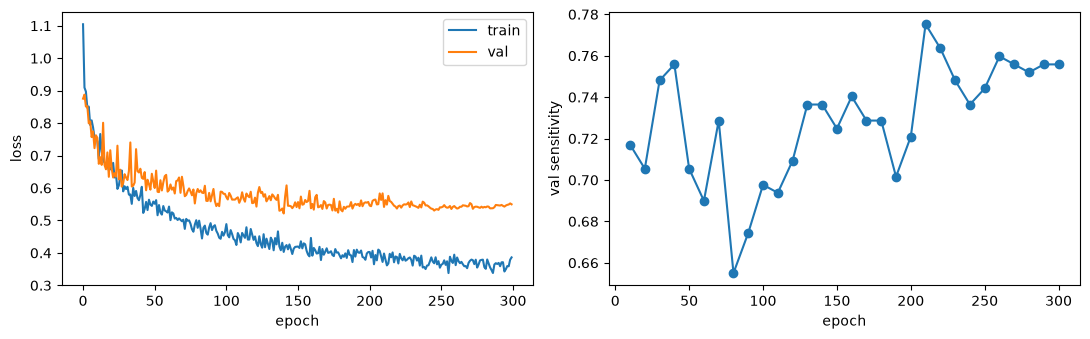

In [23]:
# CELL 11 - Train (resumable: rerun this cell any time and it continues from the last saved epoch)
import os, pickle, time

FORCE_RETRAIN = False      # True = start from scratch (old checkpoints are archived, not deleted). Set back to False right after
SAVE_EVERY    = 1          # epochs between resume checkpoints (the files are small)
CKPT_LAST = CACHE.parent / "stage1_last.pt"     # full training state: model, optimizer, scheduler, scaler, history
CKPT_BEST = CACHE.parent / "stage1_best.pt"     # best weights by validation score (used by Cell 12 / 15)
HARD_F    = CACHE.parent / "stage1_hard.pkl"    # hard-negative centres mined in Cell 12b

def save_ckpt(path, **state):
    tmp = Path(str(path) + ".tmp"); torch.save(state, tmp); os.replace(tmp, path)   # atomic: never half-written

def load_ckpt(path):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:                                                              # older PyTorch without weights_only
        return torch.load(path, map_location=device)

model = Stage1UNet().to(device)
criterion = BiasDiceBCELoss(bias=5.0, pos_weight=10.0)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.01)
use_amp = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
start_epoch, best_score, history, val_log = 1, -1e9, [], []

if FORCE_RETRAIN:
    tag = time.strftime("%Y%m%d_%H%M%S")
    for f in (CKPT_LAST, CKPT_BEST):
        if f.exists():
            f.rename(f.with_name(f"{f.stem}_old_{tag}{f.suffix}")); print("archived", f.name, "->", f"{f.stem}_old_{tag}{f.suffix}")
    print("starting from scratch (set FORCE_RETRAIN = False again so a restart resumes instead)")
elif CKPT_LAST.exists():
    ck = load_ckpt(CKPT_LAST)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["opt"])
    scheduler.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, best_score, history, val_log = ck["epoch"] + 1, ck["best_score"], ck["history"], ck["val_log"]
    if ck.get("epochs") != EPOCHS:
        print(f"WARNING: checkpoint was made with EPOCHS={ck.get('epochs')} but EPOCHS={EPOCHS} now; "
              f"the LR schedule keeps its old length. Set FORCE_RETRAIN = True to restart with the new value.")
    print(f"resumed from epoch {ck['epoch']} / {EPOCHS} (best score {best_score:.3f})")
    if start_epoch > EPOCHS:
        print("training already finished - nothing to do")
else:
    print("no checkpoint found - starting from scratch")

if HARD_F.exists():                                                                # hard negatives from Cell 12b
    hard = pickle.load(open(HARD_F, "rb"))
    if len(hard) == len(train_ds.hard):
        train_ds.hard = hard; print("loaded hard-negative centres:", sum(len(h) for h in hard))

for epoch in range(start_epoch, EPOCHS + 1):
    model.train(); tr = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(xb)
        loss = criterion(logits.float(), yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
        scaler.step(optimizer); scaler.update(); tr += loss.item()
    scheduler.step(); tr /= len(train_loader)

    model.eval(); va = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            va += criterion(model(xb.to(device)).float(), yb.to(device)).item()
    va /= len(val_loader); history.append((tr, va))
    msg = f"epoch {epoch:03d} | train {tr:.4f} | val {va:.4f} | lr {scheduler.get_last_lr()[0]:.2e}"

    if epoch % EVAL_EVERY == 0 or epoch == EPOCHS:
        r = score(predict_all(model, val_subj), val_subj, EVAL_THR, verbose=False)
        sc = r["sens"] - 0.01 * max(0.0, r["fp_pp"] - FP_BUDGET)
        val_log.append((epoch, r["sens"], r["fp_pp"], sc))
        msg += f" | VAL sens={r['sens']:.1%} prec={r['prec']:.1%} FP/pt={r['fp_pp']:.1f} score={sc:.3f}"
        if sc > best_score:
            best_score = sc; torch.save(model.state_dict(), CKPT_BEST); msg += "  *best*"
    print(msg, flush=True)

    if epoch % SAVE_EVERY == 0 or epoch == EPOCHS:                                 # resume point (after best_score is updated)
        save_ckpt(CKPT_LAST, model=model.state_dict(), opt=optimizer.state_dict(), sched=scheduler.state_dict(),
                  scaler=scaler.state_dict(), epoch=epoch, best_score=best_score,
                  history=history, val_log=val_log, epochs=EPOCHS)

if history:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([h[0] for h in history], label="train"); ax[0].plot([h[1] for h in history], label="val")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
    if val_log:
        ax[1].plot([v[0] for v in val_log], [v[1] for v in val_log], marker="o")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val sensitivity")
    plt.tight_layout(); plt.show()

In [24]:
# CELL 11s - Optional: where did training stop? (safe to run anytime, does not train)
for f in (CACHE.parent / "stage1_last.pt", CACHE.parent / "stage2_last.pt"):
    if f.exists():
        try:
            ck = torch.load(f, map_location="cpu", weights_only=False)
        except TypeError:
            ck = torch.load(f, map_location="cpu")
        print(f"{f.name}: last completed epoch = {ck['epoch']}, saved {time.strftime('%Y-%m-%d %H:%M', time.localtime(f.stat().st_mtime))}")
    else:
        print(f"{f.name}: not found")

stage1_last.pt: last completed epoch = 300, saved 2026-11-12 08:11
stage2_last.pt: not found


In [25]:
# CELL 12 - Threshold sweep on VAL, then TEST once
model.load_state_dict(torch.load(CACHE.parent / "stage1_best.pt", map_location=device))
val_probs = predict_all(model, val_subj)
for thr in (0.05, 0.1, 0.15, 0.2, 0.3, 0.5):
    print("VAL", end=" "); score(val_probs, val_subj, thr)

LOW_THR = 0.2          # set to the threshold giving ~90% sensitivity on VAL
test_probs = predict_all(model, test_subj)
print("TEST", end=" "); score(test_probs, test_subj, LOW_THR)

predicting: 100%|██████████| 15/15 [00:54<00:00,  3.67s/it]


VAL thr=0.05 | TP=208 FP=790 FN=50 | sens=80.6% prec=20.8% F1=33.1% | FP/patient=52.67 | Dice=23.9% median RVD=444.7%
VAL thr=0.1 | TP=207 FP=688 FN=51 | sens=80.2% prec=23.1% F1=35.9% | FP/patient=45.87 | Dice=26.0% median RVD=351.1%
VAL thr=0.15 | TP=203 FP=349 FN=55 | sens=78.7% prec=36.8% F1=50.1% | FP/patient=23.27 | Dice=39.6% median RVD=152.1%
VAL thr=0.2 | TP=200 FP=313 FN=58 | sens=77.5% prec=39.0% F1=51.9% | FP/patient=20.87 | Dice=41.2% median RVD=140.5%
VAL thr=0.3 | TP=195 FP=138 FN=63 | sens=75.6% prec=58.6% F1=66.0% | FP/patient=9.20 | Dice=50.9% median RVD=87.4%
VAL thr=0.5 | TP=185 FP=67 FN=73 | sens=71.7% prec=73.4% F1=72.5% | FP/patient=4.47 | Dice=56.9% median RVD=63.4%


predicting: 100%|██████████| 15/15 [00:58<00:00,  3.89s/it]


TEST thr=0.2 | TP=140 FP=415 FN=26 | sens=84.3% prec=25.2% F1=38.8% | FP/patient=27.67 | Dice=43.2% median RVD=239.8%


{'sens': 0.8433734939759037,
 'prec': 0.25225225225225223,
 'f1': 0.38834951456310685,
 'dice': 0.43193044020360566,
 'rvd_med': 2.3977011494252873,
 'fp_pp': 27.666666666666668,
 'TP': 140,
 'FP': 415,
 'FN': 26}

In [26]:
# CELL 12b - Mine false positives on TRAIN patients and feed them back to the sampler
def mine_hard_negatives(model, subjects, dataset, thr=0.2, min_vox=10, max_per_subj=40):
    name2k = {n: k for k, n in enumerate(dataset.names)}; total = 0
    for s in tqdm(subjects, desc="mining"):
        img = np.load(CACHE / f"{s.name}_img.npy"); gt = (np.load(CACHE / f"{s.name}_seg.npy") > 0).astype(np.uint8)
        pred = predict_volume(model, img) > thr
        pl, npr = ndimage.label(pred, structure=S26)
        if npr == 0:
            continue
        idx = list(range(1, npr + 1))
        touches = np.array(ndimage.maximum(gt, pl, idx))
        sizes = np.array(ndimage.sum(pred, pl, idx))
        cents = np.round(np.array(ndimage.center_of_mass(pred, pl, idx))).astype(int)
        keep = [(sz, c) for sz, c, t in zip(sizes, cents, touches) if t == 0 and sz >= min_vox]
        keep = sorted(keep, key=lambda t: -t[0])[:max_per_subj]
        dataset.hard[name2k[s.name]] = np.array([c for _, c in keep], dtype=int).reshape(-1, 3)
        total += len(keep)
    print("hard-negative centres stored:", total)

mine_hard_negatives(model, train_subj, train_ds)
import pickle
pickle.dump(train_ds.hard, open(CACHE.parent / "stage1_hard.pkl", "wb"))   # Cell 11 reloads these automatically
# To retrain with them: set FORCE_RETRAIN = True in Cell 11 ONCE (old checkpoints are archived),
# run it, then set FORCE_RETRAIN = False again. Then rerun Cell 12, 12c, 12d.

mining: 100%|██████████| 75/75 [07:01<00:00,  5.62s/it]

hard-negative centres stored: 778


In [27]:
# CELL 12c - Detection by lesion size (sensitivity per GT size, false positives per predicted size)
def diagnose(model, subjects, thr=0.2):
    gt_rows, fp_rows = [], []          # (size_voxels, detected?) / (size_voxels, is_fp?)
    for s in subjects:
        img = np.load(CACHE / f"{s.name}_img.npy"); gt = np.load(CACHE / f"{s.name}_seg.npy")
        pred = (predict_volume(model, img) > thr) & (img[0] != 0)      # keep inside brain only
        gl, ng = ndimage.label(gt, structure=S26); pl, npr = ndimage.label(pred, structure=S26)
        hit_g = set(np.unique(gl[(pl > 0) & (gl > 0)])); hit_p = set(np.unique(pl[(pl > 0) & (gl > 0)]))
        for i, sz in enumerate(ndimage.sum(gt, gl, range(1, ng + 1)), 1):
            gt_rows.append((sz, i in hit_g))
        for i, sz in enumerate(ndimage.sum(pred, pl, range(1, npr + 1)), 1):
            fp_rows.append((sz, i not in hit_p))
    bins = [0, 30, 100, 500, 1e9]       # voxels; ~mm^3 if spacing is about 1 mm
    for lo, hi in zip(bins[:-1], bins[1:]):
        g = [d for sz, d in gt_rows if lo <= sz < hi]
        f = [x for sz, x in fp_rows if lo <= sz < hi]
        print(f"{lo:>4.0f}-{hi:<6.0f} GT n={len(g):3d} sens={np.mean(g) if g else float('nan'):.0%} | "
              f"pred n={len(f):3d} FP={sum(f)}")

diagnose(model, val_subj, thr=0.2)

   0-30     GT n=141 sens=66% | pred n=252 FP=223
  30-100    GT n= 73 sens=90% | pred n=136 FP=55
 100-500    GT n= 36 sens=92% | pred n= 96 FP=33
 500-1000000000 GT n=  8 sens=100% | pred n= 19 FP=2


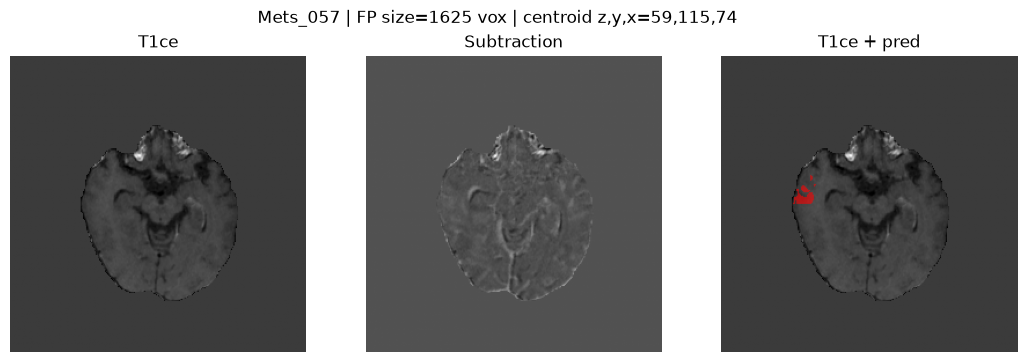

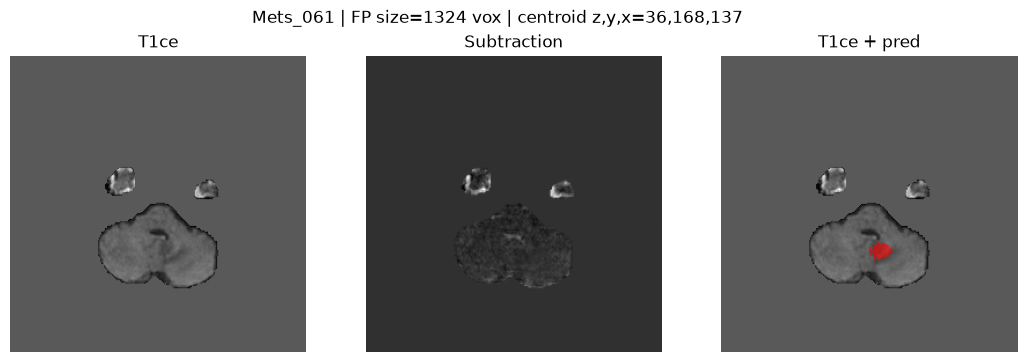

In [28]:
# CELL 12d - Look at the largest false-positive blobs
def show_big_fps(model, subjects, thr=0.2, min_vox=500, max_show=6):
    shown = 0
    for s in subjects:
        img = np.load(CACHE / f"{s.name}_img.npy").astype(np.float32); gt = np.load(CACHE / f"{s.name}_seg.npy")
        pred = predict_volume(model, img) > thr
        pl, npr = ndimage.label(pred, structure=S26)
        gl = ndimage.label(gt, structure=S26)[0]
        sizes = ndimage.sum(pred, pl, range(1, npr + 1))
        for i, sz in enumerate(sizes, 1):
            if sz >= min_vox and not (gl[pl == i] > 0).any():          # big FP: touches no GT lesion
                z, y, x = [int(c) for c in ndimage.center_of_mass(pl == i)]
                fig, ax = plt.subplots(1, 3, figsize=(13, 4))
                for a, (arr, t) in zip(ax, [(img[0], "T1ce"), (img[2], "Subtraction"), (img[0], "T1ce + pred")]):
                    a.imshow(arr[z], cmap="gray"); a.axis("off"); a.set_title(f"{t}")
                ax[2].imshow(np.ma.masked_equal((pl[z] == i), 0), cmap="autumn", alpha=0.6)
                fig.suptitle(f"{s.name} | FP size={int(sz)} vox | centroid z,y,x={z},{y},{x}")
                plt.show(); shown += 1
                if shown >= max_show: return

show_big_fps(model, val_subj)

In [29]:
# CELL 13 - Metastasis proposals for Stage 2 (box margin derived from voxel spacing)
def extract_expanded_proposals(prob, threshold=LOW_THR, spacing=SPACING, margin_mm=2.0):
    """prob: (D,H,W) probability map -> list of (z,y,x) slice tuples, boxes grown by margin_mm."""
    labeled, _ = ndimage.label(prob > threshold, structure=S26)
    pad = [int(np.ceil(margin_mm / s)) for s in spacing]
    boxes = []
    for sl in ndimage.find_objects(labeled):
        if sl is None:
            continue
        boxes.append(tuple(slice(max(s.start - p, 0), min(s.stop + p, n))
                           for s, p, n in zip(sl, pad, prob.shape)))
    return boxes

s = val_subj[0]
prob = predict_volume(model, np.load(CACHE / f"{s.name}_img.npy"))
gt = np.load(CACHE / f"{s.name}_seg.npy")
boxes = extract_expanded_proposals(prob)
print(f"{s.name}: {len(boxes)} proposals vs {ndimage.label(gt, structure=S26)[1]} ground-truth lesions")

Mets_067: 20 proposals vs 7 ground-truth lesions


In [30]:
# CELL 13b - Check that everything stage 2 needs is defined (run after a kernel restart)
need = ["S26", "dice_rvd", "detection_counts", "predict_volume", "predict_all", "score",
        "BiasDiceBCELoss", "Stage1UNet", "PatchDataset", "train_loader", "val_loader",
        "train_subj", "val_subj", "test_subj", "EVAL_EVERY", "EVAL_THR", "FP_BUDGET", "EPOCHS", "LR", "PATCH",
        "IN_CH", "CHANNEL_NAMES", "RUN_NAME", "EXTRA_SEQ"]
print("MISSING:", [n for n in need if n not in globals()])
print("run folder:", CACHE.parent, "| channels:", CHANNEL_NAMES)

MISSING: []
run folder: D:\Brain Metastases\Notebook\Dataset\bravo_flair | channels: ['T1ce', 'T1', 'Sub', 'BRAVO', 'FLAIR']


## Stage 2: proposals, classifier, combined evaluation

In [31]:
# CELL 14 - Stage 2 config + proposal utilities
import os, pickle
from collections import defaultdict

STAGE1_CKPT    = CACHE.parent / "stage1_best.pt"
LOW_THR        = 0.2     # proposal threshold on VAL/TEST (set to your stage 1 choice)
TRAIN_PROP_THR = 0.03    # lower threshold on TRAIN patients: stage 1 has seen them, so its proposals
                         # there are cleaner than on new patients; a lower cut adds realistic false positives
HIGH_THR       = 0.5     # final-segmentation threshold (tuned in Cell 19)
MARGIN_MM      = 2.0     # box expansion, as in the paper
MIN_CROP       = 24      # tiny proposals are enlarged around their centre using real image context
MAX_CROP       = 96      # larger crops are downsampled
ADD_GT_POSITIVES = True  # True = also add jittered ground-truth lesion boxes as positives (not in the paper)
S2_CACHE = CACHE.parent / "stage2_cache"; S2_CACHE.mkdir(exist_ok=True)

def save_ckpt(path, **state):
    tmp = Path(str(path) + ".tmp"); torch.save(state, tmp); os.replace(tmp, path)   # atomic: never half-written

def load_ckpt(path):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:                                                              # older PyTorch without weights_only
        return torch.load(path, map_location=device)

def get_proposals(prob, thr, gt=None, spacing=SPACING, margin_mm=MARGIN_MM):
    """Connected components of prob > thr -> list of dicts (box grown by margin_mm, label = touches a GT lesion)."""
    lab, n = ndimage.label(prob > thr, structure=S26)
    if n == 0:
        return [], lab
    idx = list(range(1, n + 1))
    pad = [int(np.ceil(margin_mm / s)) for s in spacing]
    vox = np.bincount(lab.ravel(), minlength=n + 1)[1:]
    pmax = ndimage.maximum(prob, lab, idx); pmean = ndimage.mean(prob, lab, idx)
    touch = ndimage.maximum((gt > 0).astype(np.uint8), lab, idx) if gt is not None else np.zeros(n)
    props = []
    for i, sl in enumerate(ndimage.find_objects(lab)):
        box = tuple((max(s.start - p, 0), min(s.stop + p, N)) for s, p, N in zip(sl, pad, prob.shape))
        props.append(dict(comp=i + 1, box=box, vox=int(vox[i]), pmax=float(pmax[i]),
                          pmean=float(pmean[i]), label=int(touch[i] > 0)))
    return props, lab

def gt_boxes(gt, spacing=SPACING, margin_mm=MARGIN_MM):
    lab, n = ndimage.label(gt > 0, structure=S26)
    pad = [int(np.ceil(margin_mm / s)) for s in spacing]
    return [dict(comp=-1, label=1, vox=0, pmax=1.0, pmean=1.0,
                 box=tuple((max(s.start - p, 0), min(s.stop + p, N)) for s, p, N in zip(sl, pad, gt.shape)))
            for sl in ndimage.find_objects(lab)]

def crop_proposal(img, box, min_size=MIN_CROP, max_size=MAX_CROP, jitter=0, rng=None):
    """img (3,D,H,W) array/memmap, box ((z0,z1),(y0,y1),(x0,x1)) -> float32 tensor (3,d,h,w)."""
    sl = []
    for (a, b), N in zip(box, img.shape[1:]):
        if jitter and rng is not None:
            a += int(rng.integers(-jitter, jitter + 1)); b += int(rng.integers(-jitter, jitter + 1))
            if b <= a: b = a + 1
        size = min(max(b - a, min_size), N)
        s = int(np.clip((a + b) // 2 - size // 2, 0, max(N - size, 0)))
        sl.append(slice(s, s + size))
    x = torch.from_numpy(np.asarray(img[(slice(None),) + tuple(sl)], dtype=np.float32))
    m = max(x.shape[1:])
    if m > max_size:
        x = F.interpolate(x[None], scale_factor=max_size / m, mode="trilinear", align_corners=False)[0]
    return x

In [32]:
# CELL 15 - Stage 1 -> proposals for every patient (cached on disk)
# The cache is rebuilt automatically when LOW_THR, TRAIN_PROP_THR, ADD_GT_POSITIVES or stage1_best.pt change.
FORCE_REBUILD = False        # True = rebuild no matter what
ROWS_F = S2_CACHE / "rows.pkl"
CFG = dict(low=LOW_THR, train=TRAIN_PROP_THR, gt=ADD_GT_POSITIVES,
           ckpt=int(STAGE1_CKPT.stat().st_mtime) if STAGE1_CKPT.exists() else 0)
have_probs = all((S2_CACHE / f"{s.name}_prob.npy").exists() for s in list(val_subj) + list(test_subj))
cached = pickle.load(open(ROWS_F, "rb")) if ROWS_F.exists() else None

if cached is not None and cached.get("cfg") == CFG and have_probs and not FORCE_REBUILD:
    train_rows, val_rows, test_rows = cached["train"], cached["val"], cached["test"]
    print("loaded cached proposals:", len(train_rows), len(val_rows), len(test_rows))
else:
    model = Stage1UNet().to(device)
    model.load_state_dict(torch.load(STAGE1_CKPT, map_location=device)); model.eval()

    def build_rows(subjects, thr, split, save_prob):
        rows, n_gt, n_hit = [], 0, 0
        for s in tqdm(subjects, desc=f"stage 1 -> proposals [{split}]"):
            img = np.load(CACHE / f"{s.name}_img.npy"); gt = np.load(CACHE / f"{s.name}_seg.npy")
            prob = predict_volume(model, img).astype(np.float16)       # quantise first so evaluation reproduces the same components
            if save_prob:
                np.save(S2_CACHE / f"{s.name}_prob.npy", prob)
            props, _ = get_proposals(prob.astype(np.float32), thr, gt)
            for p in props:
                p["subject"] = s.name
            rows += props
            if split != "train":                                       # stage 1 recall = ceiling for the pipeline
                tp, _, fn = detection_counts(prob.astype(np.float32) > thr, gt); n_hit += tp; n_gt += tp + fn
            if split == "train" and ADD_GT_POSITIVES:
                g = gt_boxes(gt)
                for p in g: p["subject"] = s.name
                rows += g
        if n_gt:
            print(f"  stage 1 recall on {split}: {n_hit}/{n_gt} = {n_hit / n_gt:.1%} (stage 2 cannot exceed this)")
        pos = sum(r["label"] for r in rows)
        print(f"  {split}: {len(rows)} proposals | positives {pos} ({pos / max(len(rows), 1):.0%}) | negatives {len(rows) - pos}")
        return rows

    train_rows = build_rows(train_subj, TRAIN_PROP_THR, "train", save_prob=False)
    val_rows   = build_rows(val_subj,   LOW_THR,        "val",   save_prob=True)
    test_rows  = build_rows(test_subj,  LOW_THR,        "test",  save_prob=True)
    pickle.dump(dict(train=train_rows, val=val_rows, test=test_rows, cfg=CFG), open(ROWS_F, "wb"))

stage 1 -> proposals [train]: 100%|██████████| 75/75 [07:03<00:00,  5.64s/it]


  train: 6468 proposals | positives 1966 (30%) | negatives 4502


stage 1 -> proposals [val]: 100%|██████████| 15/15 [01:28<00:00,  5.91s/it]


  stage 1 recall on val: 200/258 = 77.5% (stage 2 cannot exceed this)
  val: 503 proposals | positives 190 (38%) | negatives 313


stage 1 -> proposals [test]: 100%|██████████| 15/15 [01:28<00:00,  5.91s/it]

  stage 1 recall on test: 140/166 = 84.3% (stage 2 cannot exceed this)
  test: 537 proposals | positives 122 (23%) | negatives 415


In [33]:
# CELL 16 - Stage 2 network: multi-level CNN, adaptive average pooling per level, multi-scale concatenation
class MultiScaleFPNet(nn.Module):
    def __init__(self, in_ch=IN_CH, chans=(16, 32, 64, 128), red=32, pool=2, hidden=64, drop=0.5):   # IN_CH from Cell 2
        super().__init__()
        cs = (in_ch,) + tuple(chans)
        self.blocks = nn.ModuleList([ResBlock3D(cs[i], cs[i + 1]) for i in range(4)])    # ResBlock3D from Cell 7
        self.maxpool = nn.MaxPool3d(2)
        self.apool = nn.AdaptiveAvgPool3d(pool)                                          # same output size for any crop size
        self.reduce = nn.ModuleList([nn.Conv3d(c, red, 1) for c in chans])               # 1x1x1 conv per level
        self.fuse = nn.Conv3d(red * 4, hidden, 1)
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(hidden * pool ** 3, 1)

    def forward(self, x):
        pads = []
        for d in reversed(x.shape[2:]):                                                  # guarantee >= 8 voxels per axis
            pads += [0, max(8 - d, 0)]
        if any(pads):
            x = F.pad(x, pads)
        feats = []
        for i, blk in enumerate(self.blocks):
            x = blk(x if i == 0 else self.maxpool(x))
            feats.append(self.reduce[i](self.apool(x)))
        f = F.relu(self.fuse(torch.cat(feats, 1)))
        return self.head(self.drop(f.flatten(1)))                                        # logit (B,1): metastasis vs false positive

with torch.no_grad():
    for shp in [(1, IN_CH, 24, 24, 24), (1, IN_CH, 40, 60, 33)]:
        print(shp, "->", tuple(MultiScaleFPNet()(torch.randn(*shp)).shape))

(1, 5, 24, 24, 24) -> (1, 1)
(1, 5, 40, 60, 33) -> (1, 1)


In [34]:
# CELL 17 - Dataset + training (selection = fraction of FPs removed while keeping 98% of true proposals on VAL)
# Resumable: rerun this cell and it continues from stage2_last.pt, unless the proposals/settings changed
# (then it starts from scratch automatically). S2_FORCE = True also forces a fresh start.
S2_EPOCHS, ACC, S2_LR = 40, 16, 1e-3          # batch size 1 (variable crop sizes) + gradient accumulation
S2_FORCE = False                              # True = ignore the saved checkpoint and train from scratch (set back to False after)

_IMG = {}
def get_img(name):
    if name not in _IMG:
        _IMG[name] = np.load(CACHE / f"{name}_img.npy", mmap_mode="r")
    return _IMG[name]

class ProposalDataset(Dataset):
    def __init__(self, rows, augment=False):
        self.rows, self.augment = rows, augment
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]; rng = np.random.default_rng()
        x = crop_proposal(get_img(r["subject"]), r["box"], jitter=2 if self.augment else 0, rng=rng)
        if self.augment:
            if rng.random() < 0.5:
                x = x.flip(-1)                                                  # left-right flip
            x = x * float(rng.uniform(0.9, 1.1)) + float(rng.normal(0, 0.1)) * (x != 0).float()
        return x, torch.tensor(float(r["label"]))

@torch.no_grad()
def classify_rows(net, rows):
    net.eval(); out = []
    for r in tqdm(rows, desc="stage 2", leave=False):
        x = crop_proposal(get_img(r["subject"]), r["box"])[None].to(device)
        out.append(torch.sigmoid(net(x)).item())
    return np.array(out)

def auc_score(p, y):
    from scipy.stats import rankdata
    n1 = int(y.sum()); n0 = len(y) - n1
    return (rankdata(p)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else float("nan")

def fp_removed(p, y, keep=0.98):
    t = np.quantile(p[y == 1], 1 - keep)
    return float((p[y == 0] < t).mean())

y_val = np.array([r["label"] for r in val_rows])
n_pos = sum(r["label"] for r in train_rows); n_neg = len(train_rows) - n_pos
net2 = MultiScaleFPNet().to(device)
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(min(n_neg / max(n_pos, 1), 4.0), device=device))
opt = torch.optim.Adam(net2.parameters(), lr=S2_LR, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=S2_EPOCHS, eta_min=S2_LR * 0.01)
loader = DataLoader(ProposalDataset(train_rows, augment=True), batch_size=1, shuffle=True, num_workers=0)
best, S2_CKPT, S2_LAST = -1.0, CACHE.parent / "stage2_best.pt", CACHE.parent / "stage2_last.pt"
S2_SIG = dict(cfg=CFG, n_train=len(train_rows), n_val=len(val_rows), epochs=S2_EPOCHS)   # identifies which proposals this run belongs to
start2 = 1
if S2_LAST.exists() and not S2_FORCE:                         # resume after a restart / interruption
    ck = load_ckpt(S2_LAST)
    if ck.get("sig") == S2_SIG:
        net2.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start2, best = ck["epoch"] + 1, ck["best"]; print(f"stage 2 resumed from epoch {ck['epoch']} / {S2_EPOCHS} (best {best:.1%})")
        if start2 > S2_EPOCHS:
            print("stage 2 training already finished - nothing to do")
    else:
        print("saved stage 2 checkpoint belongs to different proposals/settings -> training from scratch")
else:
    print("stage 2: training from scratch")

for epoch in range(start2, S2_EPOCHS + 1):
    net2.train(); tot = 0.0; opt.zero_grad(set_to_none=True)
    for i, (x, y) in enumerate(loader, 1):
        loss = crit(net2(x.to(device)).squeeze(1), y.to(device)) / ACC
        loss.backward(); tot += loss.item() * ACC
        if i % ACC == 0 or i == len(loader):
            torch.nn.utils.clip_grad_norm_(net2.parameters(), 5.0); opt.step(); opt.zero_grad(set_to_none=True)
    sched.step()
    pv = classify_rows(net2, val_rows)
    sc, auc = fp_removed(pv, y_val), auc_score(pv, y_val)
    msg = f"epoch {epoch:02d} | train loss {tot / len(loader):.4f} | VAL AUC {auc:.3f} | FPs removed @98% TP kept {sc:.1%}"
    if sc > best:
        best = sc; torch.save(net2.state_dict(), S2_CKPT); msg += "  *best*"
    print(msg, flush=True)
    save_ckpt(S2_LAST, model=net2.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=epoch, best=best, sig=S2_SIG)

stage 2: training from scratch


epoch 01 | train loss 0.6723 | VAL AUC 0.931 | FPs removed @98% TP kept 50.5%  *best*


epoch 02 | train loss 0.4401 | VAL AUC 0.932 | FPs removed @98% TP kept 41.5%


epoch 03 | train loss 0.3769 | VAL AUC 0.944 | FPs removed @98% TP kept 70.0%  *best*


epoch 04 | train loss 0.3507 | VAL AUC 0.947 | FPs removed @98% TP kept 64.9%


epoch 05 | train loss 0.3128 | VAL AUC 0.946 | FPs removed @98% TP kept 57.5%


... (31 outputs left out)

epoch 37 | train loss 0.0357 | VAL AUC 0.912 | FPs removed @98% TP kept 36.7%


epoch 38 | train loss 0.0393 | VAL AUC 0.910 | FPs removed @98% TP kept 37.4%


epoch 39 | train loss 0.0369 | VAL AUC 0.910 | FPs removed @98% TP kept 36.7%


epoch 40 | train loss 0.0366 | VAL AUC 0.908 | FPs removed @98% TP kept 36.7%


In [35]:
# CELL 18 - Combined two-stage evaluation helpers
def prepare_eval(subjects):
    ev = {}
    for s in subjects:
        prob = np.load(S2_CACHE / f"{s.name}_prob.npy")                          # float16, same values the proposals came from
        lab, _ = ndimage.label(prob.astype(np.float32) > LOW_THR, structure=S26)
        ev[s.name] = dict(gt=np.load(CACHE / f"{s.name}_seg.npy").astype(bool), prob=prob, lab=lab.astype(np.int32))
    return ev

def stage2_eval(ev, rows, p2, thr2, high_thr=HIGH_THR, verbose=True, tag=""):
    keep, boxes = defaultdict(list), defaultdict(list)
    for r, p in zip(rows, p2):
        if p >= thr2:                                                            # thr2=0 keeps everything = stage 1 alone
            keep[r["subject"]].append(r["comp"]); boxes[r["subject"]].append(r["box"])
    TP = FP = FN = 0; ds, rs = [], []
    for name, d in ev.items():
        km = np.zeros(int(d["lab"].max()) + 1, bool); km[np.array(keep[name], dtype=int)] = True
        tp, fp, fn = detection_counts(km[d["lab"]], d["gt"]); TP += tp; FP += fp; FN += fn
        bm = np.zeros(d["gt"].shape, bool)
        for b in boxes[name]:
            bm[tuple(slice(a, e) for a, e in b)] = True
        dice, rvd = dice_rvd((d["prob"].astype(np.float32) > high_thr) & bm, d["gt"])    # paper: boxes x high-threshold seg
        ds.append(dice); rs.append(rvd)
    sens = TP / max(TP + FN, 1); prec = TP / max(TP + FP, 1)
    out = dict(sens=sens, prec=prec, f1=2 * sens * prec / max(sens + prec, 1e-9), fp_pp=FP / len(ev),
               dice=float(np.mean(ds)), rvd=float(np.nanmedian(rs)), TP=TP, FP=FP, FN=FN)
    if verbose:
        print(f"{tag}thr2={thr2:.2f} | TP={TP} FP={FP} FN={FN} | sens={sens:.1%} prec={prec:.1%} F1={out['f1']:.1%} "
              f"| FP/patient={out['fp_pp']:.2f} | Dice={out['dice']:.1%} median RVD={out['rvd']:.1%}")
    return out

net2.load_state_dict(torch.load(S2_CKPT, map_location=device))
ev_val, ev_test = prepare_eval(val_subj), prepare_eval(test_subj)
p2_val, p2_test = classify_rows(net2, val_rows), classify_rows(net2, test_rows)
print("VAL stage-2 AUC:", round(auc_score(p2_val, y_val), 3), "| TEST AUC:", round(auc_score(p2_test, np.array([r['label'] for r in test_rows])), 3))

VAL stage-2 AUC: 0.944 | TEST AUC: 0.918


In [36]:
# CELL 18b - Is stage 2 learning anything? (needs Cell 17 and Cell 18 to have run)
p2_train = classify_rows(net2, train_rows)                      # no augmentation
y_tr = np.array([r["label"] for r in train_rows]); y_te = np.array([r["label"] for r in test_rows])
for name, p, y in [("train", p2_train, y_tr), ("val", p2_val, y_val), ("test", p2_test, y_te)]:
    print(f"{name:5s} AUC={auc_score(p, y):.3f} | mean p: positives {p[y == 1].mean():.2f}, negatives {p[y == 0].mean():.2f}")

print("\nVAL operating points (per proposal):")
for t in (0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    kept = (p2_val[y_val == 1] >= t).mean(); removed = (p2_val[y_val == 0] < t).mean()
    print(f"  thr2={t:.2f}: true proposals kept {kept:.1%} | false positives removed {removed:.1%}")

vox_val = np.array([r["vox"] for r in val_rows])
print("\nVAL true proposals rejected at thr2=0.3, by proposal size (voxels):")
for lo, hi in [(0, 30), (30, 100), (100, 500), (500, 10**9)]:
    m = (y_val == 1) & (vox_val >= lo) & (vox_val < hi)
    print(f"  {lo:>3}-{hi:<10} n={int(m.sum()):3d} rejected={(p2_val[m] < 0.3).mean() if m.any() else float('nan'):.0%}")

train AUC=0.965 | mean p: positives 0.92, negatives 0.18
val   AUC=0.944 | mean p: positives 0.91, negatives 0.27
test  AUC=0.918 | mean p: positives 0.94, negatives 0.40

VAL operating points (per proposal):
  thr2=0.02: true proposals kept 100.0% | false positives removed 19.2%
  thr2=0.05: true proposals kept 100.0% | false positives removed 37.7%
  thr2=0.10: true proposals kept 98.4% | false positives removed 52.4%
  thr2=0.20: true proposals kept 97.9% | false positives removed 64.2%
  thr2=0.30: true proposals kept 97.9% | false positives removed 70.3%
  thr2=0.40: true proposals kept 96.8% | false positives removed 73.2%
  thr2=0.50: true proposals kept 94.2% | false positives removed 76.0%
  thr2=0.60: true proposals kept 93.7% | false positives removed 79.2%
  thr2=0.70: true proposals kept 92.1% | false positives removed 82.1%

VAL true proposals rejected at thr2=0.3, by proposal size (voxels):
    0-30         n= 29 rejected=3%
   30-100        n= 81 rejected=4%
  100-500  

In [37]:
# CELL 19 - Choose THR2 and HIGH_THR on VAL (best F1 within the allowed sensitivity drop), then report
MAX_SENS_DROP = 0.05                                    # paper lost ~1.5%; relaxed because VAL has only ~170 true proposals
base_val = stage2_eval(ev_val, val_rows, p2_val, 0.0, verbose=False)
print(f"VAL stage 1 only: sens={base_val['sens']:.1%} prec={base_val['prec']:.1%} F1={base_val['f1']:.1%} FP/patient={base_val['fp_pp']:.2f}")

cands = [(float(t), stage2_eval(ev_val, val_rows, p2_val, float(t), verbose=False)) for t in np.arange(0.02, 0.96, 0.02)]
for t, r in cands[::5]:
    print(f"  thr2={t:.2f}: sens={r['sens']:.1%} prec={r['prec']:.1%} F1={r['f1']:.1%} FP/patient={r['fp_pp']:.2f}")
ok = [(t, r) for t, r in cands if r["sens"] >= base_val["sens"] - MAX_SENS_DROP and r["f1"] > base_val["f1"]]
if ok:
    THR2 = max(ok, key=lambda tr: tr[1]["f1"])[0]
    print("chosen THR2:", THR2)
else:
    THR2 = 0.0
    print("no threshold improves VAL F1 within the allowed sensitivity drop -> stage 2 is not separating yet (see Cell 18b)")

best_d = -1
for h in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    r = stage2_eval(ev_val, val_rows, p2_val, THR2, high_thr=h, verbose=False)
    print(f"  HIGH_THR={h}: Dice={r['dice']:.1%} median RVD={r['rvd']:.1%}")
    if r["dice"] > best_d:
        best_d, HIGH_THR = r["dice"], h
print("chosen HIGH_THR:", HIGH_THR)

print("\n=== TEST (chosen on VAL) ===")
s1 = stage2_eval(ev_test, test_rows, p2_test, 0.0, HIGH_THR, tag="stage 1 only | ")
s2 = stage2_eval(ev_test, test_rows, p2_test, THR2, HIGH_THR, tag="stage 1+2    | ")
print("paper (stage 1+2): sens=90.0% prec=56.0% FP/patient=4.57 Dice=81% RVD=20%")

VAL stage 1 only: sens=77.5% prec=39.0% F1=51.9% FP/patient=20.87
  thr2=0.02: sens=77.5% prec=44.2% F1=56.3% FP/patient=16.87
  thr2=0.12: sens=76.4% prec=57.9% F1=65.9% FP/patient=9.53
  thr2=0.22: sens=76.0% prec=64.5% F1=69.8% FP/patient=7.20
  thr2=0.32: sens=76.0% prec=68.5% F1=72.1% FP/patient=6.00
  thr2=0.42: sens=74.8% prec=69.9% F1=72.3% FP/patient=5.53
  thr2=0.52: sens=73.3% prec=72.1% F1=72.7% FP/patient=4.87
  thr2=0.62: sens=72.9% prec=74.9% F1=73.9% FP/patient=4.20
  thr2=0.72: sens=71.7% prec=77.7% F1=74.6% FP/patient=3.53
  thr2=0.82: sens=69.4% prec=81.0% F1=74.7% FP/patient=2.80
  thr2=0.92: sens=60.9% prec=85.3% F1=71.0% FP/patient=1.80
chosen THR2: 0.64
  HIGH_THR=0.3: Dice=58.0% median RVD=75.7%
  HIGH_THR=0.4: Dice=59.1% median RVD=66.7%
  HIGH_THR=0.5: Dice=61.1% median RVD=54.3%
  HIGH_THR=0.6: Dice=62.2% median RVD=48.5%
  HIGH_THR=0.7: Dice=63.2% median RVD=42.4%
  HIGH_THR=0.8: Dice=64.0% median RVD=35.2%
  HIGH_THR=0.9: Dice=65.3% median RVD=25.8%
chosen 

In [38]:
# CELL 19b - size-aware stage 2 thresholds (small proposals get a lower bar)
SMALL_VOX = 30
vox_val  = np.array([r["vox"] for r in val_rows]); vox_test = np.array([r["vox"] for r in test_rows])

def eff(p, vox, ts, tl):
    """Shift scores so that one global cut of 0.5 applies the per-size thresholds."""
    return p - np.where(vox < SMALL_VOX, ts, tl) + 0.5

base_val = stage2_eval(ev_val, val_rows, p2_val, 0.0, verbose=False)
res = []
for ts in (0.0, 0.01, 0.02, 0.05, 0.1):                          # threshold for proposals < SMALL_VOX voxels
    for tl in (0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6):               # threshold for larger proposals
        r = stage2_eval(ev_val, val_rows, eff(p2_val, vox_val, ts, tl), 0.5, verbose=False)
        res.append((ts, tl, r))
print(f"VAL stage 1 only: sens={base_val['sens']:.1%} prec={base_val['prec']:.1%} F1={base_val['f1']:.1%} FP/patient={base_val['fp_pp']:.2f}")
ok = [x for x in res if x[2]["sens"] >= base_val["sens"] - MAX_SENS_DROP and x[2]["f1"] > base_val["f1"]]
for ts, tl, r in sorted(ok, key=lambda x: -x[2]["f1"])[:8]:
    print(f"  small<{SMALL_VOX}vox thr={ts:.2f} | large thr={tl:.2f}: sens={r['sens']:.1%} prec={r['prec']:.1%} F1={r['f1']:.1%} FP/patient={r['fp_pp']:.2f}")

if ok:
    TS, TL, _ = max(ok, key=lambda x: x[2]["f1"])
    print("chosen: small thr", TS, "| large thr", TL)
    print("\n=== TEST (chosen on VAL) ===")
    stage2_eval(ev_test, test_rows, p2_test, 0.0, HIGH_THR, tag="stage 1 only    | ")
    stage2_eval(ev_test, test_rows, eff(p2_test, vox_test, TS, TL), 0.5, HIGH_THR, tag="stage 1+2 (sized)| ")
else:
    print("no size-aware setting improves VAL F1 within the allowed sensitivity drop")

VAL stage 1 only: sens=77.5% prec=39.0% F1=51.9% FP/patient=20.87
  small<30vox thr=0.10 | large thr=0.40: sens=75.6% prec=60.4% F1=67.1% FP/patient=8.53
  small<30vox thr=0.10 | large thr=0.60: sens=74.0% prec=61.2% F1=67.0% FP/patient=8.07
  small<30vox thr=0.10 | large thr=0.30: sens=76.0% prec=59.8% F1=66.9% FP/patient=8.80
  small<30vox thr=0.10 | large thr=0.50: sens=74.0% prec=60.1% F1=66.3% FP/patient=8.47
  small<30vox thr=0.10 | large thr=0.20: sens=76.0% prec=58.7% F1=66.2% FP/patient=9.20
  small<30vox thr=0.10 | large thr=0.10: sens=76.4% prec=56.9% F1=65.2% FP/patient=9.93
  small<30vox thr=0.10 | large thr=0.05: sens=77.1% prec=55.6% F1=64.6% FP/patient=10.60
  small<30vox thr=0.05 | large thr=0.40: sens=76.0% prec=54.4% F1=63.4% FP/patient=10.93
chosen: small thr 0.1 | large thr 0.4

=== TEST (chosen on VAL) ===
stage 1 only    | thr2=0.00 | TP=140 FP=415 FN=26 | sens=84.3% prec=25.2% F1=38.8% | FP/patient=27.67 | Dice=56.1% median RVD=12.7%
stage 1+2 (sized)| thr2=0.50

## Segmentation diagnostics (run after Cell 19)

In [39]:
# CELL 20 - Segmentation diagnosis: lesion-wise Dice and volume ratio of the FINAL segmentation, by lesion size
def lesion_seg_report(ev, rows, p2, thr2, high_thr, bins=((0, 30), (30, 100), (100, 500), (500, 10**9))):
    keep, boxes = defaultdict(list), defaultdict(list)
    for r, p in zip(rows, p2):
        if p >= thr2:
            keep[r["subject"]].append(r["comp"]); boxes[r["subject"]].append(r["box"])
    recs = []                                                    # (gt_voxels, detected, dice, pred/gt volume ratio)
    for name, d in ev.items():
        km = np.zeros(int(d["lab"].max()) + 1, bool); km[np.array(keep[name], dtype=int)] = True
        det_mask = km[d["lab"]]
        bm = np.zeros(d["gt"].shape, bool)
        for b in boxes[name]:
            bm[tuple(slice(a, e) for a, e in b)] = True
        seg = (d["prob"].astype(np.float32) > high_thr) & bm
        sl, _ = ndimage.label(seg, structure=S26); sizes = np.bincount(sl.ravel())
        gl, ng = ndimage.label(d["gt"], structure=S26)
        for i, o in enumerate(ndimage.find_objects(gl), 1):
            g = gl[o] == i; gs = int(g.sum())
            detected = bool(det_mask[o][g].any())
            comps = np.unique(sl[o][g]); comps = comps[comps > 0]
            ps = int(sizes[comps].sum()) if len(comps) else 0
            inter = int((sl[o][g] > 0).sum())
            recs.append((gs, detected, 2 * inter / (ps + gs) if ps + gs else 0.0, ps / gs))
    recs = np.array(recs, dtype=float)
    print(f"final segmentation, thr2={thr2}, HIGH_THR={high_thr}")
    for lo, hi in bins:
        m = (recs[:, 0] >= lo) & (recs[:, 0] < hi)
        det = m & (recs[:, 1] > 0); seg_ok = m & (recs[:, 2] > 0)
        if m.any():
            print(f"  {lo:>3}-{hi:<10} GT n={int(m.sum()):3d} | detected {det.sum() / m.sum():.0%} | "
                  f"lesion Dice (detected) mean {recs[det, 2].mean() if det.any() else float('nan'):.0%} "
                  f"| median pred/GT volume {np.median(recs[seg_ok, 3]) if seg_ok.any() else float('nan'):.2f}")
    det = recs[:, 1] > 0
    print(f"  ALL    GT n={len(recs)} | detected {det.mean():.0%} | lesion Dice (detected) mean {recs[det, 2].mean():.0%}")

lesion_seg_report(ev_test, test_rows, p2_test, THR2, HIGH_THR)

final segmentation, thr2=0.64, HIGH_THR=0.9
    0-30         GT n= 60 | detected 62% | lesion Dice (detected) mean 29% | median pred/GT volume 1.76
   30-100        GT n= 49 | detected 96% | lesion Dice (detected) mean 44% | median pred/GT volume 1.19
  100-500        GT n= 33 | detected 88% | lesion Dice (detected) mean 65% | median pred/GT volume 0.99
  500-1000000000 GT n= 24 | detected 92% | lesion Dice (detected) mean 70% | median pred/GT volume 1.09
  ALL    GT n=166 | detected 81% | lesion Dice (detected) mean 49%


In [40]:
# CELL 21 - Final segmentation with a per-lesion relative threshold (instead of one global HIGH_THR)
def final_seg_rel(d, keep_ids, alpha, floor=None):
    """Inside each kept stage-1 component keep voxels with prob > alpha * (that component's max prob)."""
    floor = LOW_THR if floor is None else floor
    lab, prob = d["lab"], d["prob"].astype(np.float32)
    n = int(lab.max())
    if n == 0 or len(keep_ids) == 0:
        return np.zeros(lab.shape, bool)
    pm = np.zeros(n + 1, np.float32); pm[1:] = ndimage.maximum(prob, lab, list(range(1, n + 1)))
    km = np.zeros(n + 1, bool); km[np.array(keep_ids, dtype=int)] = True
    return km[lab] & (prob > np.maximum(alpha * pm[lab], floor))

def lesion_stats(seg, gt, det):
    sl, _ = ndimage.label(seg, structure=S26); sizes = np.bincount(sl.ravel())
    gl, ng = ndimage.label(gt, structure=S26); out = []
    for i, o in enumerate(ndimage.find_objects(gl), 1):
        g = gl[o] == i; gs = int(g.sum())
        comps = np.unique(sl[o][g]); comps = comps[comps > 0]
        ps = int(sizes[comps].sum()) if len(comps) else 0
        inter = int((sl[o][g] > 0).sum())
        out.append((gs, bool(det[o][g].any()), 2 * inter / (ps + gs) if ps + gs else 0.0, ps / gs))
    return out

def seg_eval(ev, rows, p2, thr2, alpha=None, high_thr=0.8, verbose=False, tag=""):
    keep = defaultdict(list)
    for r, p in zip(rows, p2):
        if p >= thr2:
            keep[r["subject"]].append(r["comp"])
    pat, recs = [], []
    for name, d in ev.items():
        km = np.zeros(int(d["lab"].max()) + 1, bool); km[np.array(keep[name], dtype=int)] = True
        if alpha is None:
            seg = km[d["lab"]] & (d["prob"].astype(np.float32) > high_thr)
        else:
            seg = final_seg_rel(d, keep[name], alpha)
        pat.append(dice_rvd(seg, d["gt"])[0]); recs += lesion_stats(seg, d["gt"], km[d["lab"]])
    recs = np.array(recs, dtype=float); det = recs[:, 1] > 0
    out = dict(patient_dice=float(np.mean(pat)), lesion_dice=float(recs[det, 2].mean()))
    if verbose:
        print(f"{tag} patient Dice={out['patient_dice']:.1%} | lesion Dice (detected)={out['lesion_dice']:.1%}")
        for lo, hi in ((0, 30), (30, 100), (100, 500), (500, 10**9)):
            m = (recs[:, 0] >= lo) & (recs[:, 0] < hi) & det
            if m.any():
                print(f"    {lo:>3}-{hi:<10} n={int(m.sum()):3d} lesion Dice {recs[m, 2].mean():.0%} | median pred/GT volume {np.median(recs[m & (recs[:, 2] > 0), 3]):.2f}")
    return out

print("VAL, global thresholds (what you have now):")
for h in (0.5, 0.8):
    r = seg_eval(ev_val, val_rows, p2_val, THR2, None, h); print(f"  high_thr={h}: patient Dice={r['patient_dice']:.1%} | lesion Dice={r['lesion_dice']:.1%}")
print("VAL, relative threshold per lesion:")
best_a, best_v = None, -1
for a in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
    r = seg_eval(ev_val, val_rows, p2_val, THR2, a); print(f"  alpha={a}: patient Dice={r['patient_dice']:.1%} | lesion Dice={r['lesion_dice']:.1%}")
    if r["patient_dice"] + r["lesion_dice"] > best_v:
        best_a, best_v = a, r["patient_dice"] + r["lesion_dice"]
ALPHA = best_a; print("chosen ALPHA:", ALPHA)
seg_eval(ev_test, test_rows, p2_test, THR2, None, HIGH_THR, verbose=True, tag="TEST global HIGH_THR |")
seg_eval(ev_test, test_rows, p2_test, THR2, ALPHA, verbose=True, tag=f"TEST relative alpha={ALPHA} |")

VAL, global thresholds (what you have now):
  high_thr=0.5: patient Dice=61.1% | lesion Dice=51.0%
  high_thr=0.8: patient Dice=64.0% | lesion Dice=51.7%
VAL, relative threshold per lesion:
  alpha=0.3: patient Dice=57.4% | lesion Dice=50.6%
  alpha=0.4: patient Dice=58.2% | lesion Dice=52.0%
  alpha=0.5: patient Dice=59.3% | lesion Dice=53.1%
  alpha=0.6: patient Dice=60.2% | lesion Dice=53.5%
  alpha=0.7: patient Dice=61.1% | lesion Dice=53.9%
  alpha=0.8: patient Dice=62.1% | lesion Dice=54.2%
chosen ALPHA: 0.8
TEST global HIGH_THR | patient Dice=58.3% | lesion Dice (detected)=48.7%
      0-30         n= 37 lesion Dice 29% | median pred/GT volume 1.76
     30-100        n= 47 lesion Dice 44% | median pred/GT volume 1.19
    100-500        n= 29 lesion Dice 65% | median pred/GT volume 0.99
    500-1000000000 n= 22 lesion Dice 70% | median pred/GT volume 1.09
TEST relative alpha=0.8 | patient Dice=56.7% | lesion Dice (detected)=53.5%
      0-30         n= 37 lesion Dice 44% | median p

{'patient_dice': 0.5671533619316763, 'lesion_dice': 0.5348192762432037}

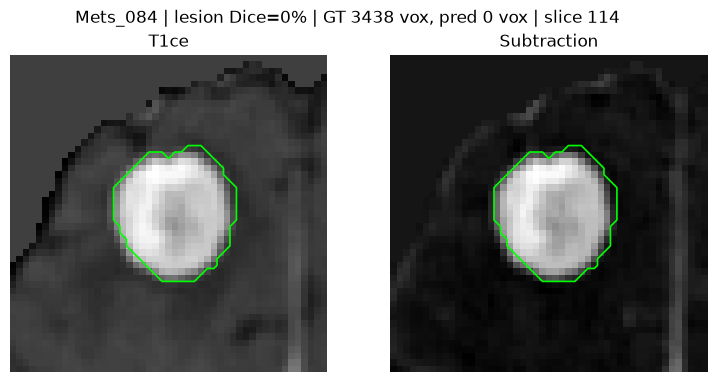

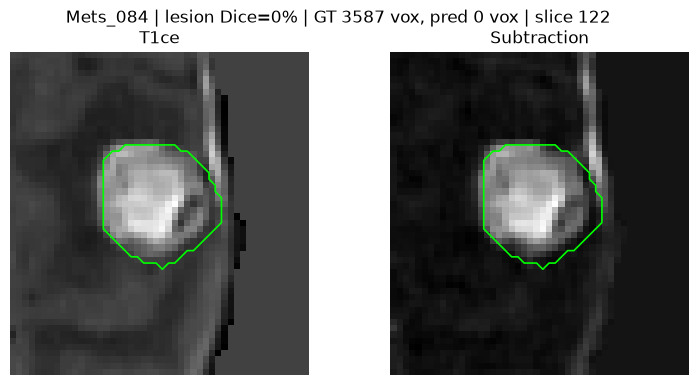

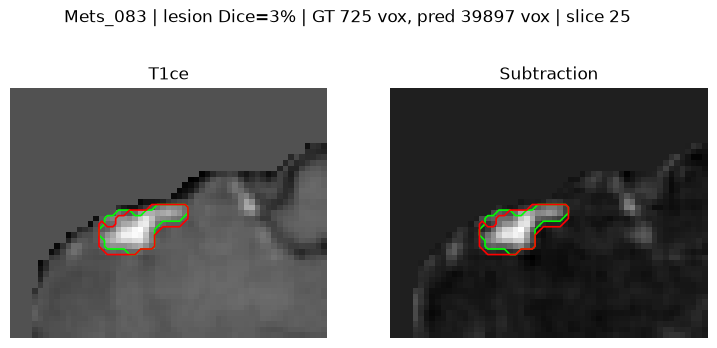

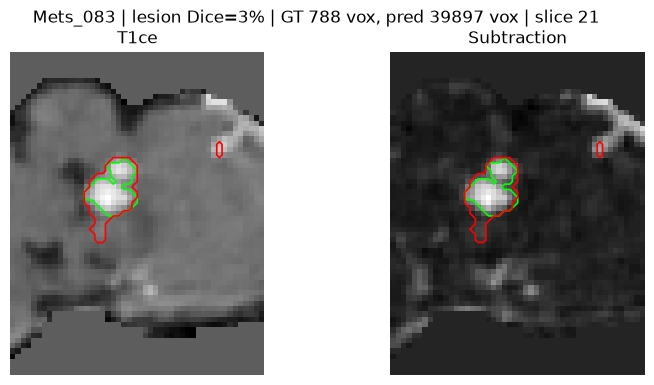

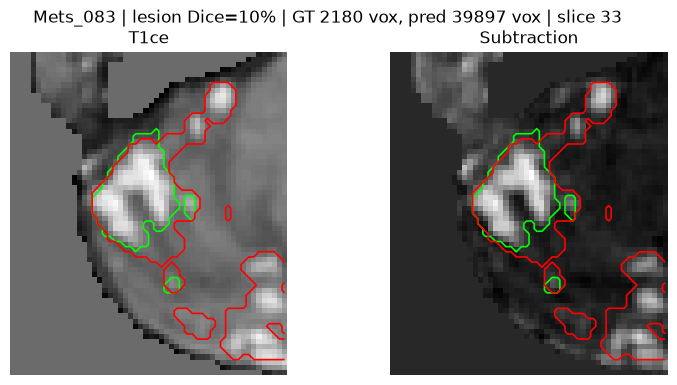

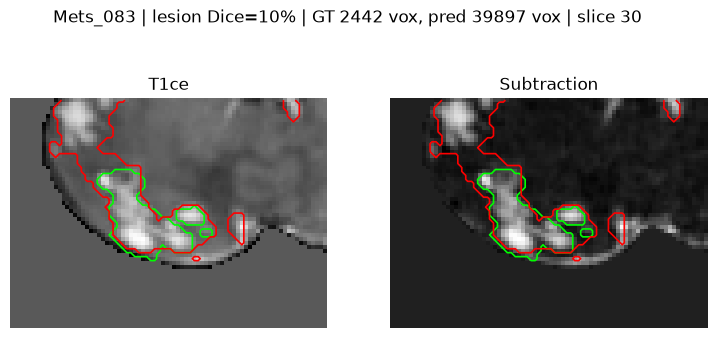

In [41]:
# CELL 22 - Look at the worst-segmented large lesions (GT green, prediction red) to see WHY Dice is low
def show_worst_large(ev, rows, p2, thr2, alpha, subjects, min_vox=500, k=6, margin=14):
    keep = defaultdict(list)
    for r, p in zip(rows, p2):
        if p >= thr2:
            keep[r["subject"]].append(r["comp"])
    items = []
    for name, d in ev.items():
        seg = final_seg_rel(d, keep[name], alpha)
        gl, ng = ndimage.label(d["gt"], structure=S26); sl, _ = ndimage.label(seg, structure=S26); sizes = np.bincount(sl.ravel())
        for i, o in enumerate(ndimage.find_objects(gl), 1):
            g = gl[o] == i; gs = int(g.sum())
            if gs < min_vox:
                continue
            comps = np.unique(sl[o][g]); comps = comps[comps > 0]
            ps = int(sizes[comps].sum()) if len(comps) else 0
            items.append((2 * int((sl[o][g] > 0).sum()) / max(ps + gs, 1), name, i, gs, ps, o))
    items.sort(key=lambda t: t[0])
    for dice, name, i, gs, ps, o in items[:k]:
        d = ev[name]; img = np.load(CACHE / f"{name}_img.npy", mmap_mode="r")
        gl = ndimage.label(d["gt"], structure=S26)[0]; seg = final_seg_rel(d, keep[name], alpha)
        z = int(np.mean([o[0].start, o[0].stop - 1]))
        ys = slice(max(o[1].start - margin, 0), o[1].stop + margin); xs = slice(max(o[2].start - margin, 0), o[2].stop + margin)
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
        for a, ch, t in zip(ax, (0, 2), ("T1ce", "Subtraction")):
            a.imshow(np.asarray(img[ch, z, ys, xs], dtype=np.float32), cmap="gray"); a.axis("off"); a.set_title(t)
            if (gl[z, ys, xs] == i).any(): a.contour(gl[z, ys, xs] == i, levels=[0.5], colors="lime", linewidths=1.2)
            if seg[z, ys, xs].any(): a.contour(seg[z, ys, xs], levels=[0.5], colors="red", linewidths=1.2)
        fig.suptitle(f"{name} | lesion Dice={dice:.0%} | GT {gs} vox, pred {ps} vox | slice {z}"); plt.show()

show_worst_large(ev_test, test_rows, p2_test, THR2, ALPHA, test_subj)